# Exp21 — Shared computation vs shared representation, on the same items and layers

Two axes, measured at the **answer position** (last prompt token) of every prompt, per layer, per task, per language, against an anchor language (EN; FR for gender, since EN has no gender).

**Computation (causal): floor-corrected cross-language patching compat.**
Take a recipient prompt in language L (label y) and patch in the activation from a *donor* with the opposite label.
- cross donor: same item in the anchor language, label flipped
- floor donor: same language L, a different surface variant (different template / premise form), label flipped

Transfer = how far the recipient's margin (logP cand1 - logP cand0, full-sequence) moves toward the donor's answer. **compat = cross transfer / same-language transfer**, reported only where the same-language transfer is large enough to be meaningful (FLOOR_MIN_FRAC of the mean clean margin), per your Exp14/16 floor rule. Patched sites: `resid` (block output), `attn` (attention write, pre-residual-add), `mlp` (MLP write).

**Representation (geometric), same items, same layers, no intervention.**
Per-language mean-centered states (the Exp17 lesson: otherwise the language axis dominates).
- `R_cos`: cosine between the label direction (mean y=1 minus mean y=0) in the anchor and in L, divided by the within-L split-half floor
- `R_probe`: the anchor's label direction applied to L's states (accuracy above chance), divided by L's own leave-one-out accuracy above chance
- `R_lang`: cosine between uncentered language means (how far the languages sit apart)
- `lens`: logit-lens margin per layer (when the answer appears)

**Tasks (single aligned decision position, opposite-label donor exists):** IOI (EN names in every language), negation, agreement (head number, congruent/attractor mix), gender. Cells are limited to those that passed Exp18-20.
**Not in this notebook:** word order, translation, classifier, numeral polarity. Word order decides over a sentence, not at one position, and the others lack an aligned opposite-label donor; they need their own design.

Caveats: 24 items per cell (12 bases x 2 labels) is a pilot-size sample; at late layers a cross donor's state encodes a donor-language word that the recipient cannot read, so low late-layer compat for lexical tasks is the language-specific output stage, not necessarily non-sharing; and the hook code has not been run on a real model.

In [1]:
# CELL 1 — config + data (edit MODELS / GPU_ID / CELLS only)
import os
GPU_ID = 2
os.environ.setdefault("CUDA_VISIBLE_DEVICES", str(GPU_ID))
import json, math, random, itertools, warnings
from pathlib import Path
import numpy as np
OUT = Path("exp21_results"); OUT.mkdir(exist_ok=True)

MODELS = {"bloom-1b7": "bigscience/bloom-1b7", "bloom-7b1": "bigscience/bloom-7b1"}
def prepend_bos(key): return "gemma" in key
N_BASES, LAYER_STRIDE, SEED = 12, 2, 0        # items per cell = 2 * N_BASES (balanced labels)
KINDS = ("resid", "attn", "mlp")
FLOOR_MIN_FRAC = 0.30                         # compat valid only where same-language transfer >= this * mean|clean margin|
CELLS = {"ioi": ["en","fr","es","de","zh","ar","hi"], "negation": ["en","fr","es","zh"], "agreement": ["en","fr","es","hi"], "gender": ["fr","es","ar","hi"]}
ANCHOR     = {"ioi": "en", "negation": "en", "agreement": "en", "gender": "fr"}
ANCHOR_ALT = {"ioi": "fr", "negation": "fr", "agreement": "fr", "gender": "es"}      # donor language when the recipient IS the anchor
NV = {"ioi": 4, "negation": 2, "agreement": 2, "gender": 3}                          # surface variants per task
PRED_TASK_EPS = {"ioi": 0, "negation": 1, "agreement": 2, "gender": 3}                # ordinal, from task structure, written before running
SEP = {"zh": ""}

EN_NAMES = ["Mary","John","Tom","Anna","James","Sarah","David","Emily","Michael","Laura","Peter","Julia"]
TEMPLATES = {   # IOI: n1, n2 = first two mentions; n3 = repeated subject; final word constant per language
 "en": ["Then, {n1} and {n2} went to the shop. {n3} gave a drink to","After lunch, {n1} and {n2} went to the park. {n3} gave a book to",
        "When {n1} and {n2} got to the office, {n3} gave a letter to","Yesterday {n1} and {n2} were at the school. {n3} handed a pen to"],
 "fr": ["Ensuite, {n1} et {n2} sont allés au magasin. {n3} a donné une boisson à","Après le déjeuner, {n1} et {n2} sont allés au parc. {n3} a donné un livre à",
        "Quand {n1} et {n2} sont arrivés au bureau, {n3} a donné une lettre à","Hier, {n1} et {n2} étaient à l'école. {n3} a tendu un stylo à"],
 "es": ["Luego, {n1} y {n2} fueron a la tienda. {n3} le dio una bebida a","Después del almuerzo, {n1} y {n2} fueron al parque. {n3} le dio un libro a",
        "Cuando {n1} y {n2} llegaron a la oficina, {n3} le dio una carta a","Ayer {n1} y {n2} estaban en la escuela. {n3} le pasó un bolígrafo a"],
 "de": ["Dann gingen {n1} und {n2} zum Laden. {n3} gab ein Getränk an","Nach dem Mittagessen gingen {n1} und {n2} in den Park. {n3} gab ein Buch an",
        "Als {n1} und {n2} im Büro ankamen, gab {n3} einen Brief an","Gestern waren {n1} und {n2} in der Schule. {n3} reichte einen Stift an"],
 "zh": ["然后，{n1}和{n2}去了商店。{n3}把一杯饮料给","午饭后，{n1}和{n2}去了公园。{n3}把一本书给","当{n1}和{n2}到了办公室，{n3}把一封信给","昨天{n1}和{n2}在学校。{n3}把一支笔给"],
 "ar": ["ثم ذهب {n1} مع {n2} إلى المتجر. أعطى {n3} مشروبا إلى","بعد الغداء ذهب {n1} مع {n2} إلى الحديقة. أعطى {n3} كتابا إلى",
        "عندما وصل {n1} مع {n2} إلى المكتب، أعطى {n3} رسالة إلى","أمس كان {n1} مع {n2} في المدرسة. أعطى {n3} قلما إلى"],
 "hi": ["फिर {n1} और {n2} दुकान गए। {n3} ने","दोपहर के खाने के बाद {n1} और {n2} पार्क गए। {n3} ने","जब {n1} और {n2} दफ़्तर पहुँचे, तब {n3} ने","कल {n1} और {n2} स्कूल में थे। {n3} ने"],
}
NEG_FMT = {"en": ("{s1} is not {x}, so {s2} is", "{s1} is {x}, so {s2} is"), "fr": ("{s1} n'est pas {x}, donc {s2} est", "{s1} est {x}, donc {s2} est"),
           "es": ("{s1} no está {x}, así que {s2} está", "{s1} está {x}, así que {s2} está"), "zh": ("{s1}不是{x}，所以{s2}是", "{s1}是{x}，所以{s2}是")}
NEG = {   # (s1, s2, adj_a, adj_b); variant 0 = negated premise, 1 = affirmative premise
 "en": [("The door","the door","open","closed"),("The glass","the glass","full","empty"),("The soup","the soup","hot","cold"),("The towel","the towel","wet","dry"),("The room","the room","clean","dirty")],
 "fr": [("La porte","la porte","ouverte","fermée"),("Le verre","le verre","plein","vide"),("La soupe","la soupe","chaude","froide"),("La serviette","la serviette","mouillée","sèche"),("La chambre","la chambre","propre","sale")],
 "es": [("La puerta","la puerta","abierta","cerrada"),("El vaso","el vaso","lleno","vacío"),("La sopa","la sopa","caliente","fría"),("La toalla","la toalla","mojada","seca"),("La habitación","la habitación","limpia","sucia")],
 "zh": [("门","门","开着的","关着的"),("杯子","杯子","满的","空的"),("汤","汤","热的","冷的"),("毛巾","毛巾","湿的","干的"),("房间","房间","干净的","脏的")],
}
AGR = {   # head (sg, pl) x attractor PP (sg, pl) x verb (sg, pl); cand0 = singular form, cand1 = plural form
 "en": dict(heads=[("The author","The authors"),("The key","The keys"),("The teacher","The teachers"),("The pilot","The pilots")], pps=[("of the book","of the books"),("by the door","by the doors"),("near the car","near the cars")], verbs=[("is","are"),("was","were"),("has","have")]),
 "fr": dict(heads=[("L'auteur","Les auteurs"),("Le professeur","Les professeurs"),("Le pilote","Les pilotes"),("Le directeur","Les directeurs")], pps=[("du livre","des livres"),("de la porte","des portes"),("de la voiture","des voitures")], verbs=[("est","sont"),("a","ont"),("était","étaient")]),
 "es": dict(heads=[("El autor","Los autores"),("El profesor","Los profesores"),("El piloto","Los pilotos"),("El director","Los directores")], pps=[("del libro","de los libros"),("de la puerta","de las puertas"),("del coche","de los coches")], verbs=[("es","son"),("tiene","tienen"),("estaba","estaban")]),
 "hi": dict(heads=[("लड़का","लड़के"),("कुत्ता","कुत्ते"),("घोड़ा","घोड़े"),("बच्चा","बच्चे")], pps=[("मेज़ के पास","मेज़ों के पास"),("दरवाज़े के पास","दरवाज़ों के पास"),("कार के पास","कारों के पास")], verbs=[("है","हैं"),("था","थे")]),
}
GEN = {   # nouns: first 4 masculine, last 4 feminine (index-paired); cand0 = masculine adjective, cand1 = feminine adjective
 "fr": dict(fmt="Notre {n} est très", adjs=[("petit","petite"),("grand","grande"),("joli","jolie")], nouns=["livre","arbre","jardin","camion","table","voiture","main","nuit"]),
 "es": dict(fmt="Mi {n} es muy", adjs=[("nuevo","nueva"),("viejo","vieja"),("bonito","bonita")], nouns=["libro","coche","día","mapa","casa","mesa","mano","foto"]),
 "ar": dict(fmt="{n}", adjs=[("جديد","جديدة"),("كبير","كبيرة"),("جميل","جميلة")], nouns=["الباب","الكتاب","القلم","البيت","السيارة","الطاولة","الشمس","العين"]),
 "hi": dict(fmt="यह {n} बहुत", adjs=[("बड़ा","बड़ी"),("अच्छा","अच्छी"),("छोटा","छोटी")], nouns=["दरवाज़ा","कमरा","घर","पानी","कुर्सी","मेज़","किताब","रात"]),
}
print("config ok")

config ok


In [2]:
# CELL 2 — tokenizer helpers, aligned item grid (label y = index of the correct candidate; flipping y keeps the base)
def enc(tok, text): return tok(text, add_special_tokens=False)["input_ids"]
def new_tokens(tok, prefix, cont):
    a, b = enc(tok, prefix), enc(tok, prefix + cont)
    return b[len(a):] if b[:len(a)] == a else None

def all_bases(task, seed):
    if task == "ioi":
        cores = [(a, b, o) for a, b in itertools.permutations(EN_NAMES, 2) for o in ("ABBA", "BABA")]
    elif task == "negation": cores = [(p,) for p in range(5)]
    elif task == "agreement": cores = [(h, p, c) for h in range(4) for p in range(3) for c in (True, False)]
    elif task == "gender": cores = [(i,) for i in range(4)]
    bs = [(c, v) for c in cores for v in range(NV[task])]
    random.Random(seed).shuffle(bs); return bs

def render(task, lang, core, v, y):
    # returns (prefix, cand0, cand1, sep)
    sep = SEP.get(lang, " ")
    if task == "ioi":
        a, b, o = core; io, s = (a, b) if y == 0 else (b, a); n1, n2 = (io, s) if o == "ABBA" else (s, io)
        return TEMPLATES[lang][v].format(n1=n1, n2=n2, n3=s), a, b, sep
    if task == "negation":
        s1, s2, a, b = NEG[lang][core[0]]; fneg, faff = NEG_FMT[lang]
        x = (b if y == 0 else a) if v == 0 else (a if y == 0 else b)
        return (fneg if v == 0 else faff).format(s1=s1, s2=s2, x=x), a, b, sep
    if task == "agreement":
        h, p, cong = core; d = AGR[lang]; an = y if cong else 1 - y
        head, pp = d["heads"][h][y], d["pps"][p][an]
        prefix = f"{pp} {'का' if y == 0 else 'के'} {head}" if lang == "hi" else f"{head} {pp}"
        vs, vp = d["verbs"][v % len(d["verbs"])]; return prefix, vs, vp, sep
    if task == "gender":
        d = GEN[lang]; noun = d["nouns"][core[0] + (0 if y == 0 else 4)]; m, f = d["adjs"][v]
        return d["fmt"].format(n=noun), m, f, sep

def valid_render(tok, task, lang, core, v):
    for y in (0, 1):
        pr, c0, c1, sep = render(task, lang, core, v, y)
        if not (new_tokens(tok, pr, sep + c0) and new_tokens(tok, pr, sep + c1)): return False
    return True

def build_items(tok, task, lang, donor, n_bases, seed):
    out = []
    for core, v in all_bases(task, seed):
        v2 = (v + 1) % NV[task]
        if all(valid_render(tok, task, lg, core, vv) for lg, vv in ((lang, v), (lang, v2), (donor, v))): out.append((core, v))
        if len(out) >= n_bases: break
    return [dict(core=c, variant=v, y=y) for c, v in out for y in (0, 1)]
print("helpers ok")

helpers ok


In [3]:
# CELL 3 — numpy analysis functions (no GPU)
def compat_curves(Pc, Ps, m_clean, y, boots=300, seed=0):
    # Pc, Ps: patched margins [n, n_layers] under cross / same-language donors; m_clean: [n]; y: recipient labels (donor label = 1 - y)
    sgn = (1 - 2 * y)[:, None]                                  # +1 if the donor's answer is cand1
    Tc, Ts = (Pc - m_clean[:, None]) * sgn, (Ps - m_clean[:, None]) * sgn
    scale = np.abs(m_clean).mean(); tc, ts = Tc.mean(0), Ts.mean(0); valid = ts >= FLOOR_MIN_FRAC * scale
    with np.errstate(divide="ignore", invalid="ignore"): comp = np.where(valid, tc / ts, np.nan)
    rng, n, bs = np.random.default_rng(seed), len(y), []
    for _ in range(boots):
        ix = rng.integers(0, n, n); a, b, sc = Tc[ix].mean(0), Ts[ix].mean(0), np.abs(m_clean[ix]).mean()
        with np.errstate(divide="ignore", invalid="ignore"): bs.append(np.where(b >= FLOOR_MIN_FRAC * sc, a / b, np.nan))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); lo, hi = np.nanpercentile(np.array(bs), [2.5, 97.5], axis=0)
    return dict(compat=comp, lo=lo, hi=hi, valid=valid, Tc=tc, Ts=ts, flip_c=((Pc * sgn) > 0).mean(0), flip_s=((Ps * sgn) > 0).mean(0))

def _cos(a, b):
    d = np.linalg.norm(a) * np.linalg.norm(b); return float(a @ b / d) if d > 0 else np.nan
def _dir(X, y): return X[y == 1].mean(0) - X[y == 0].mean(0)

def rep_metrics(HA, HL, y, n_split=20, seed=0, min_floor=0.30, min_ceil=0.20):
    # HA, HL: [n_items, n_layers, H] anchor / language-L states for the SAME bases and labels y
    rng, nl, rows = np.random.default_rng(seed), HL.shape[1], []
    idx1, idx0 = np.where(y == 1)[0], np.where(y == 0)[0]
    for l in range(nl):
        XA, XL = HA[:, l] - HA[:, l].mean(0), HL[:, l] - HL[:, l].mean(0)       # per-language centering
        dA, dL = _dir(XA, y), _dir(XL, y); rc = _cos(dA, dL)
        fl = []
        for _ in range(n_split):
            h1, h0 = rng.permutation(idx1), rng.permutation(idx0)
            a = np.r_[h1[:len(h1) // 2], h0[:len(h0) // 2]]; b = np.r_[h1[len(h1) // 2:], h0[len(h0) // 2:]]
            fl.append(_cos(_dir(XL[a], y[a]), _dir(XL[b], y[b])))
        floor = float(np.nanmean(fl))
        acc_x = float(((XL @ dA > 0).astype(int) == y).mean())
        loo = []
        for i in range(len(y)):
            keep = np.arange(len(y)) != i; loo.append(int((XL[i] @ _dir(XL[keep], y[keep]) > 0) == y[i]))
        acc_w = float(np.mean(loo))
        rows.append(dict(layer=l, R_cos=rc, cos_floor=floor, R_cos_norm=rc / floor if floor >= min_floor else np.nan,
                         acc_cross=acc_x, acc_within=acc_w, R_probe=(acc_x - .5) / (acc_w - .5) if acc_w - .5 >= min_ceil else np.nan,
                         R_lang=_cos(HL[:, l].mean(0), HA[:, l].mean(0))))
    return rows
print("analysis functions ok")

analysis functions ok


In [4]:
# CELL 4 — run: capture, patch, save (GPU). Results go to exp21_results/*.npz so analysis can be re-run without a GPU.
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM
dev = "cuda" if torch.cuda.is_available() else "cpu"

def get_modules(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):          # BLOOM
        bl = list(model.transformer.h)
        return dict(resid=bl, attn=[b.self_attention.dense for b in bl], mlp=[b.mlp.dense_4h_to_h for b in bl], ln_f=model.transformer.ln_f, lm_head=model.lm_head)
    bl = list(model.model.layers)                                                   # Gemma / Llama / Qwen
    return dict(resid=bl, attn=[b.self_attn.o_proj for b in bl], mlp=[b.mlp.down_proj for b in bl], ln_f=model.model.norm, lm_head=model.lm_head)

def patch_hook(p, vec):
    def hook(mod, inp, out):
        tup = isinstance(out, tuple); o = (out[0] if tup else out).clone(); o[:, p] = vec.to(o.dtype)
        return (o,) + tuple(out[1:]) if tup else o
    return hook

@torch.no_grad()
def margin(model, mods, tok, bos, prefix, c0t, c1t, patch=None):
    ids = bos + enc(tok, prefix); p = len(ids) - 1
    rows = [ids + c0t, ids + c1t]; T = max(map(len, rows)); pad = tok.pad_token_id if tok.pad_token_id is not None else 0
    inp = torch.tensor([r + [pad] * (T - len(r)) for r in rows], device=dev)
    att = torch.tensor([[1] * len(r) + [0] * (T - len(r)) for r in rows], device=dev)
    h = mods[patch[0]][patch[1]].register_forward_hook(patch_hook(p, patch[2])) if patch else None
    try: logits = model(input_ids=inp, attention_mask=att).logits
    finally:
        if h: h.remove()
    lp = []
    for r, ct in enumerate((c0t, c1t)):
        g = torch.log_softmax(logits[r, p:p + len(ct)].float(), -1); lp.append(sum(g[j, t].item() for j, t in enumerate(ct)))
    return lp[1] - lp[0]

@torch.no_grad()
def capture(model, mods, tok, bos, prefix):
    ids = bos + enc(tok, prefix); p = len(ids) - 1; nl = len(mods["resid"])
    store = {k: [None] * nl for k in KINDS}; hs = []
    for k in KINDS:
        for li, m in enumerate(mods[k]):
            def hk(mod, inp, out, k=k, li=li):
                o = out[0] if isinstance(out, tuple) else out; store[k][li] = o[0, p].detach()
            hs.append(m.register_forward_hook(hk))
    try: model(input_ids=torch.tensor([ids], device=dev))
    finally:
        for h in hs: h.remove()
    return {k: torch.stack(v) for k, v in store.items()}          # [n_layers, H]

for key, path in MODELS.items():
    tok = AutoTokenizer.from_pretrained(path); bos = [tok.bos_token_id] if prepend_bos(key) else []
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.bfloat16).to(dev).eval()
    mods = get_modules(model); nl = len(mods["resid"]); LAYERS = sorted(set(list(range(0, nl, LAYER_STRIDE)) + [nl - 1])); W = mods["lm_head"].weight
    cache = {}
    def cap(prefix):
        if prefix not in cache: cache[prefix] = capture(model, mods, tok, bos, prefix)
        return cache[prefix]
    for task, langs in CELLS.items():
        for L in langs:
            f = OUT / f"{key}__{task}__{L}.npz"
            if f.exists(): print("cached", f.name); continue
            D = ANCHOR[task] if L != ANCHOR[task] else ANCHOR_ALT[task]
            items = build_items(tok, task, L, D, N_BASES, SEED)
            if len(items) < 12: print("SKIP (too few valid bases)", key, task, L, len(items)); continue
            n, t0 = len(items), time.time()
            y = np.array([it["y"] for it in items]); mc = np.zeros(n)
            P = {(d, k): np.zeros((n, len(LAYERS))) for d in ("cross", "same") for k in KINDS}
            HL = np.zeros((n, nl, W.shape[1]), dtype=np.float32); HA = np.zeros_like(HL); lens = np.full((n, nl), np.nan)
            for i, it in enumerate(items):
                core, v, yy = it["core"], it["variant"], it["y"]; v2 = (v + 1) % NV[task]
                pr, c0, c1, sep = render(task, L, core, v, yy); c0t, c1t = new_tokens(tok, pr, sep + c0), new_tokens(tok, pr, sep + c1)
                mc[i] = margin(model, mods, tok, bos, pr, c0t, c1t)
                dc, ds = cap(render(task, D, core, v, 1 - yy)[0]), cap(render(task, L, core, v2, 1 - yy)[0])
                for dn, dcap in (("cross", dc), ("same", ds)):
                    for k in KINDS:
                        for j, l in enumerate(LAYERS): P[(dn, k)][i, j] = margin(model, mods, tok, bos, pr, c0t, c1t, patch=(k, l, dcap[k][l]))
                cl = cap(pr); HL[i] = cl["resid"].float().cpu().numpy(); HA[i] = cap(render(task, D, core, v, yy)[0])["resid"].float().cpu().numpy()
                if c0t[0] != c1t[0]:
                    with torch.no_grad(): lens[i] = (mods["ln_f"](cl["resid"]) @ (W[c1t[0]] - W[c0t[0]]).to(cl["resid"].dtype)).float().cpu().numpy()
            np.savez(f, y=y, m_clean=mc, layers=np.array(LAYERS), HL=HL, HA=HA, lens=lens, donor=np.array(D),
                     **{f"P_{d}_{k}": P[(d, k)] for d in ("cross", "same") for k in KINDS})
            print(f"saved {f.name}  n={n}  clean acc={(((mc > 0).astype(int)) == y).mean():.2f}  {time.time() - t0:.0f}s")
    del model; gc.collect(); torch.cuda.empty_cache()

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ProxyError: 302 Moved Temporarily

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/anwoy/miniconda3/envs/ke/lib/python3.10

    model      task lang donor  n  clean_acc  pred_eps  C_resid  valid_layers_resid  C_attn  valid_layers_attn  C_mlp  valid_layers_mlp  R_probe  R_cos  R_lang
bloom-1b7       ioi   ar    en 24       1.00         0     0.98                   5     NaN                  0    NaN                 0      NaN    NaN    0.83
bloom-1b7       ioi   de    en 24       0.96         0     1.13                   5    0.60                  1    NaN                 0      NaN    NaN    0.62
bloom-1b7       ioi   en    fr 24       1.00         0     1.09                   5    0.91                  1    NaN                 0      NaN    NaN    0.87
bloom-1b7       ioi   es    en 24       1.00         0     0.84                   5    0.62                  1    NaN                 0      NaN    NaN    0.88
bloom-1b7       ioi   fr    en 24       1.00         0     0.91                   5     NaN                  0    NaN                 0      NaN    NaN    0.87
bloom-1b7       ioi   hi    en 24       

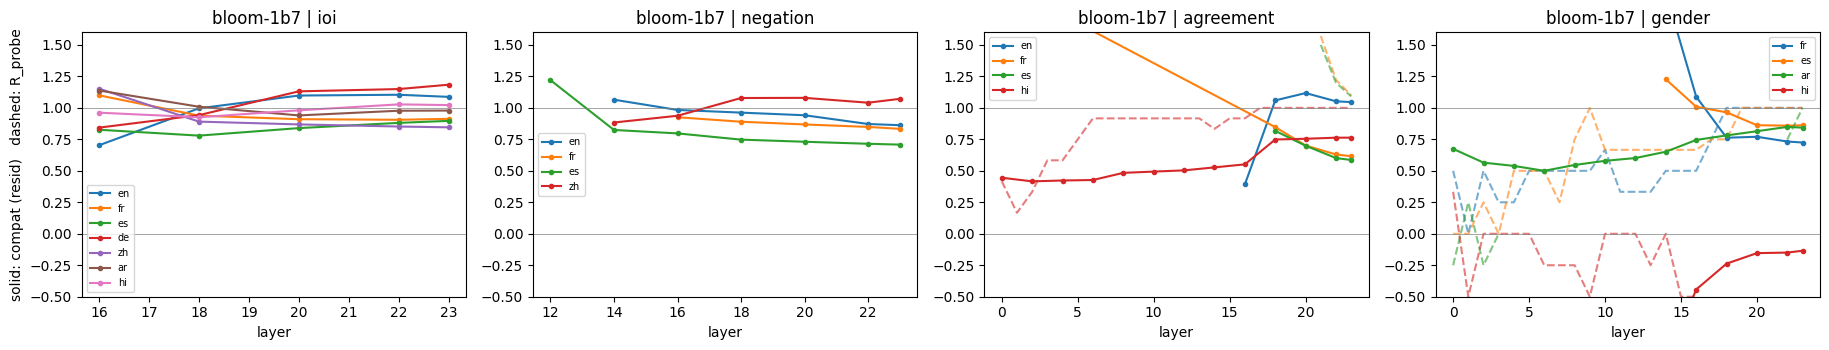

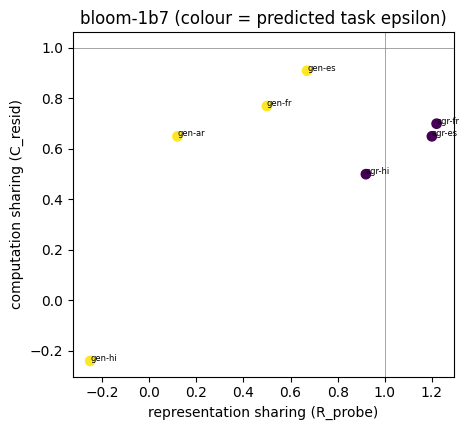

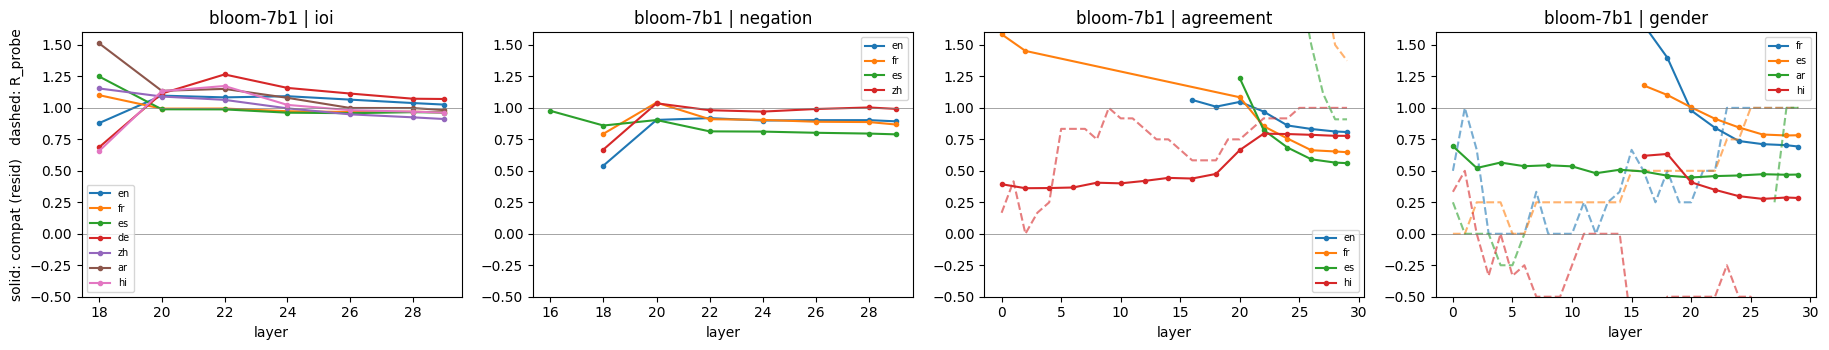

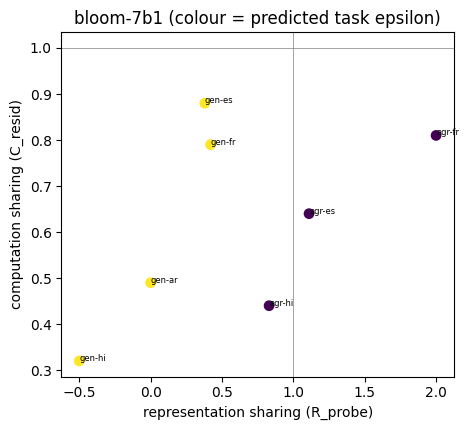

In [ ]:
# CELL 5 — analysis from saved results (no GPU): per-layer tables, summary, figures
import pandas as pd
rows_c, rows_r, rows_s = [], [], []
for f in sorted(OUT.glob("*.npz")):
    key, task, L = f.stem.split("__"); z = np.load(f); y, mc, layers = z["y"], z["m_clean"], z["layers"]
    clean_acc = float(((mc > 0).astype(int) == y).mean())
    rep = rep_metrics(z["HA"], z["HL"], y); lens_or = np.nanmean(z["lens"] * (2 * y - 1)[:, None], axis=0) if np.isfinite(z["lens"]).any() else np.full(len(rep), np.nan)
    for r in rep: r.update(model=key, task=task, lang=L, lens=float(lens_or[r["layer"]])); rows_r.append(r)
    summ = dict(model=key, task=task, lang=L, donor=str(z["donor"]), n=len(y), clean_acc=round(clean_acc, 2), pred_eps=PRED_TASK_EPS[task])
    for k in KINDS:
        cc = compat_curves(z[f"P_cross_{k}"], z[f"P_same_{k}"], mc, y)
        for j, l in enumerate(layers):
            rows_c.append(dict(model=key, task=task, lang=L, kind=k, layer=int(l), compat=cc["compat"][j], lo=cc["lo"][j], hi=cc["hi"][j], valid=bool(cc["valid"][j]),
                               T_cross=cc["Tc"][j], T_same=cc["Ts"][j], flip_cross=cc["flip_c"][j], flip_same=cc["flip_s"][j]))
        summ[f"C_{k}"] = round(float(np.nanmedian(cc["compat"])), 2) if np.isfinite(cc["compat"]).any() else np.nan
        summ[f"valid_layers_{k}"] = int(cc["valid"].sum())
    rl = pd.DataFrame(rep)
    summ["R_probe"] = round(float(rl.R_probe.median()), 2); summ["R_cos"] = round(float(rl.R_cos_norm.median()), 2); summ["R_lang"] = round(float(rl.R_lang.median()), 2)
    rows_s.append(summ)
df_c, df_r, df_s = pd.DataFrame(rows_c), pd.DataFrame(rows_r), pd.DataFrame(rows_s).sort_values(["model", "pred_eps", "task", "lang"])
pd.set_option("display.width", 250); print(df_s.to_string(index=False))
print("\nC_* = median floor-corrected compat over valid layers; R_* = median floor-corrected representation sharing over layers (nan = floor/ceiling too low to interpret).")
print("Interpret a cell only if clean_acc >= 0.75 and valid_layers > 0.")
df_c.to_csv(OUT / "compat_per_layer.csv", index=False); df_r.to_csv(OUT / "rep_per_layer.csv", index=False); df_s.to_csv(OUT / "summary.csv", index=False)

import matplotlib.pyplot as plt
for key in df_s.model.unique():
    tasks = [t for t in CELLS if ((df_s.model == key) & (df_s.task == t)).any()]
    fig, axs = plt.subplots(1, len(tasks), figsize=(4.6 * len(tasks), 3.6), squeeze=False)
    for ax, t in zip(axs[0], tasks):
        for L in CELLS[t]:
            c = df_c[(df_c.model == key) & (df_c.task == t) & (df_c.lang == L) & (df_c.kind == "resid") & df_c.valid]; r = df_r[(df_r.model == key) & (df_r.task == t) & (df_r.lang == L)]
            if len(c) == 0 and len(r) == 0: continue
            ln, = ax.plot(c.layer, c.compat, "-o", ms=3, label=L); ax.plot(r.layer, r.R_probe, "--", color=ln.get_color(), alpha=.6)
        ax.axhline(1, color="gray", lw=.5); ax.axhline(0, color="gray", lw=.5); ax.set_title(f"{key} | {t}"); ax.set_xlabel("layer"); ax.set_ylim(-.5, 1.6); ax.legend(fontsize=7)
    axs[0][0].set_ylabel("solid: compat (resid)   dashed: R_probe")
    plt.tight_layout(); plt.savefig(OUT / f"depth_{key}.png", dpi=140); plt.show()
    s = df_s[df_s.model == key]; fig, ax = plt.subplots(figsize=(4.8, 4.4))
    ax.scatter(s.R_probe, s.C_resid, c=s.pred_eps, cmap="viridis", s=45)
    for _, r in s.iterrows(): ax.annotate(f"{r.task[:3]}-{r.lang}", (r.R_probe, r.C_resid), fontsize=6)
    ax.set_xlabel("representation sharing (R_probe)"); ax.set_ylabel("computation sharing (C_resid)"); ax.set_title(f"{key} (colour = predicted task epsilon)")
    ax.axhline(1, color="gray", lw=.5); ax.axvline(1, color="gray", lw=.5); plt.tight_layout(); plt.savefig(OUT / f"quadrant_{key}.png", dpi=140); plt.show()